# Chapitre 12 - Cours 4 : justesse de bout en bout et contraintes

Un service sans état qui se trompe se corrige en redémarrant ; un système qui
**mémorise** (une base de données) garde ses erreurs, parfois pour toujours. Ce notebook
ouvre la section *Aiming for Correctness* : il couvre *The End-to-End Argument for
Databases* (exécution exactement une fois, suppression des doublons, identifiants de
requête, argument de bout en bout) et *Enforcing Constraints* (unicité, journal
partitionné, traitement d'une requête qui touche plusieurs partitions sans validation atomique).

**Plan.**

1. Pourquoi la justesse est difficile.
2. Exécution exactement une fois et suppression des doublons.
3. Identifier chaque requête de bout en bout.
4. L'argument de bout en bout.
5. Faire respecter l'unicité.
6. Une requête sur plusieurs partitions, sans validation atomique.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
SHARD, SHARDS = "partition", "partitions"

## 1. Pourquoi la justesse est difficile (section *Aiming for Correctness*)

On veut des applications **fiables et correctes** : des programmes dont la sémantique est
bien définie et comprise, même en présence de pannes. Depuis une quarantaine d'années,
l'outil de référence est la transaction (atomicité, isolation, durabilité). Ses
fondations sont pourtant plus fragiles qu'il n'y paraît : la confusion autour des
niveaux d'isolation faibles (chapitre 7) en témoigne ; certains domaines
ont abandonné les transactions pour des modèles plus performants mais à la sémantique
floue ; la « cohérence » est souvent invoquée et rarement définie. Les expériences Jepsen
de Kyle Kingsbury ont montré de grands écarts entre les garanties annoncées par certains
produits et leur comportement réel face aux pannes réseau et aux plantages. Et même avec
une base parfaite, l'application doit encore utiliser correctement des réglages
difficiles à comprendre (isolation, quorums).

Une base qui offre des transactions sérialisables ne protège pas d'un **bogue
applicatif** qui écrit des données fausses ou en supprime. C'est un argument en faveur
des données **immuables, en ajout seul** : on se remet bien plus facilement d'une erreur
si le code fautif n'a pas pu **détruire** les bonnes données. Comparons, après un
déploiement bogué qui applique une remise deux fois trop forte pendant une heure, une
table de soldes **mise à jour en place** et un **journal d'événements** dont on dérive les
soldes.

In [2]:
rng = random.Random(4)
events = []                                                 # (heure, client, montant brut, remise)
for h in range(24):
    for _ in range(200):
        events.append((h, rng.randrange(500), round(rng.uniform(5, 200), 2), 0.10))

def montant(evt, bug):
    h, c, brut, remise = evt
    r = remise * 2 if (bug and h == 13) else remise          # le déploiement bogué de 13 h
    return brut * (1 - r)

soldes_en_place = {}
for e in events:                                            # mise à jour en place : seul le résultat survit
    soldes_en_place[e[1]] = soldes_en_place.get(e[1], 0) + montant(e, bug=True)
soldes_corrects = {}
for e in events:                                            # journal : on peut tout rejouer avec le code corrigé
    soldes_corrects[e[1]] = soldes_corrects.get(e[1], 0) + montant(e, bug=False)
faux = sum(abs(soldes_en_place[c] - soldes_corrects[c]) > 1e-9 for c in soldes_corrects)
pd.DataFrame({"approche": ["table mise à jour en place", "journal immuable + rejeu corrigé"],
              "soldes faux après correction du bogue": [faux, 0],
              "comment réparer ?": ["impossible sans l'historique (montants bruts perdus)",
                                    "rejouer les événements avec le code corrigé"]})

,approche,soldes faux après correction du bogue,comment réparer ?
0,table mise à jour en place,160,impossible sans l'historique (montants bruts p...
1,journal immuable + rejeu corrigé,0,rejouer les événements avec le code corrigé


La table en place a « oublié » les montants bruts : les soldes de plusieurs centaines de
clients restent faux, et rien ne permet de savoir de combien. Le journal immuable
conserve l'entrée de chaque décision ; corriger le code et rejouer suffit. L'immuabilité
n'est pas une panacée pour autant : la suite montre une corruption plus subtile, qui
survit à des transactions parfaitement sérialisables.

> **À retenir.** Les garanties d'une base (même sérialisable) ne protègent ni des bogues
> applicatifs ni des mauvais usages. Garder les données immuables, en ajout seul, empêche
> le code fautif de détruire les bonnes données et rend la réparation possible.

## 2. Exécution exactement une fois et suppression des doublons (sections *Exactly-once execution of an operation* et *Duplicate suppression*)

Le problème de l'exécution **exactement une fois** (chapitre 11) : si le
traitement d'un message échoue, on peut abandonner (perte de données) ou réessayer ; mais
si le premier essai avait en fait réussi et que seule la confirmation s'est perdue, le
message est traité **deux fois**. Traiter deux fois est une **corruption** : facturer deux
fois un client, compter deux fois un événement. « Exactement une fois » signifie organiser
le calcul pour que l'effet final soit **le même que sans panne**, même si l'opération a
été réessayée. Le moyen le plus efficace : rendre l'opération **idempotente**, ce qui
demande souvent des métadonnées (l'ensemble des identifiants d'opérations déjà
appliquées) et du fencing lors des basculements (chapitre 8).

TCP supprime déjà les doublons de paquets grâce aux numéros de séquence, mais
**seulement au sein d'une connexion**. Or une transaction est souvent liée à une
connexion : si le client perd la connexion après avoir envoyé `COMMIT` mais avant la
réponse, il ne sait pas si la transaction est validée. S'il se reconnecte et réessaie,
il est hors du périmètre de TCP, et un virement non idempotent est exécuté deux fois.

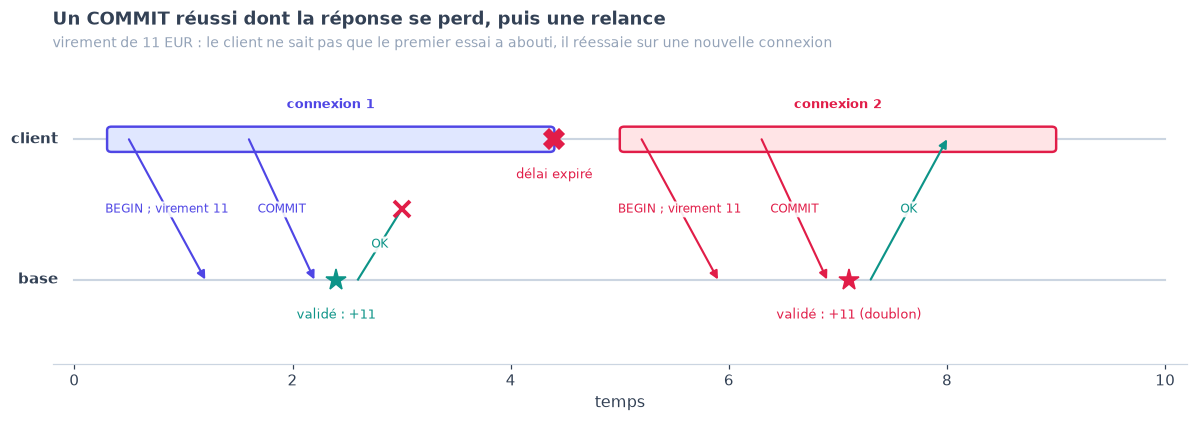

In [3]:
st = SpaceTime(["client", "base"], t_max=10, width=11, lane_height=1.6,
               title="Un COMMIT réussi dont la réponse se perd, puis une relance",
               subtitle="virement de 11 EUR : le client ne sait pas que le premier essai a abouti, il réessaie sur une nouvelle connexion")
st.op("client", 0.3, 4.4, "connexion 1", color=INDIGO)
st.msg("client", 0.5, "base", 1.2, "BEGIN ; virement 11", color=INDIGO)
st.msg("client", 1.6, "base", 2.2, "COMMIT", color=INDIGO)
st.event("base", 2.4, "validé : +11", kind="star", color=TEAL)
st.msg("base", 2.6, "client", 3.4, "OK", color=TEAL, lost=True)
st.event("client", 4.4, "délai expiré", kind="crash")
st.op("client", 5.0, 9.0, "connexion 2", color=ROSE)
st.msg("client", 5.2, "base", 5.9, "BEGIN ; virement 11", color=ROSE)
st.msg("client", 6.3, "base", 6.9, "COMMIT", color=ROSE)
st.event("base", 7.1, "validé : +11 (doublon)", kind="star", color=ROSE)
st.msg("base", 7.3, "client", 8.0, "OK", color=TEAL)
st.show()

La validation atomique (2PC) casse le lien entre connexion et transaction (le
coordinateur se reconnecte et dit à la base de valider ou d'annuler une transaction en
doute), mais ne règle pas tout : il reste le réseau entre **l'appareil de l'utilisateur**
et le serveur d'application. Un utilisateur sur une connexion mobile faible envoie un
formulaire (`POST`), perd le signal avant la réponse, voit un message d'erreur et
réessaie (« Voulez-vous vraiment renvoyer le formulaire ? » : oui, il veut que
l'opération ait lieu). Pour le serveur web c'est une nouvelle requête, pour la base une
nouvelle transaction. Simulons un client qui fait 2 000 virements de 11 EUR, et dont la
réponse se perd avec une probabilité $p$ ; à chaque perte, il réessaie (jusqu'à 5 envois).

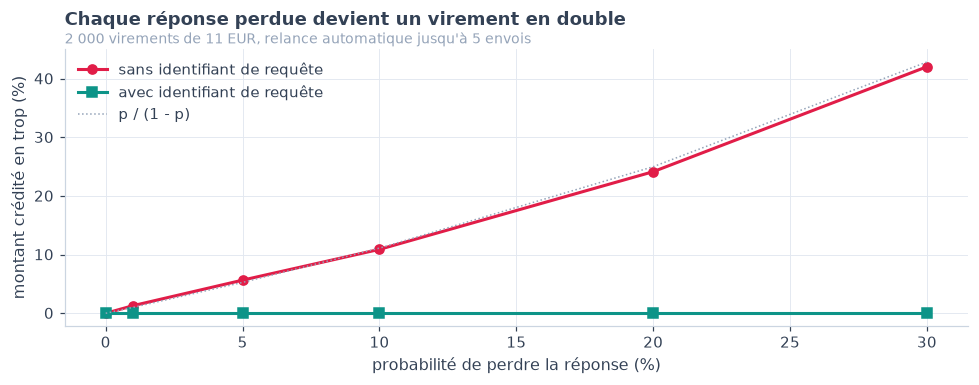

,p (réponse perdue),voulu (EUR),crédité sans identifiant,crédité avec identifiant,envois
0,0.00,22000.0,22000.0,22000.0,2000
1,0.01,22000.0,22286.0,22000.0,2026
2,0.05,22000.0,23243.0,22000.0,2113
3,0.10,22000.0,24398.0,22000.0,2218
4,0.20,22000.0,27313.0,22000.0,2483
5,0.30,22000.0,31251.0,22000.0,2841


In [4]:
ps = [0.0, 0.01, 0.05, 0.1, 0.2, 0.3]
rows = []
for p in ps:
    naive = dfl.retrying_client(dfl.make_bank_db({1: 0.0, 2: 1e6}), 2000, p, use_ids=False, seed=1)
    dedup = dfl.retrying_client(dfl.make_bank_db({1: 0.0, 2: 1e6}), 2000, p, use_ids=True, seed=1)
    rows.append({"p (réponse perdue)": p, "voulu (EUR)": naive["intended"], "crédité sans identifiant": naive["credited"],
                 "crédité avec identifiant": dedup["credited"], "envois": naive["attempts"]})
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(R.iloc[:, 0] * 100, (R.iloc[:, 2] / R.iloc[:, 1] - 1) * 100, "o-", color=ROSE, label="sans identifiant de requête")
ax.plot(R.iloc[:, 0] * 100, (R.iloc[:, 3] / R.iloc[:, 1] - 1) * 100, "s-", color=TEAL, label="avec identifiant de requête")
ax.plot(R.iloc[:, 0] * 100, [p / (1 - p) * 100 for p in R.iloc[:, 0]], color=GRAY, ls=":", lw=1, label="p / (1 - p)")
ax.set_xlabel("probabilité de perdre la réponse (%)"); ax.set_ylabel("montant crédité en trop (%)")
ax.set_title("Chaque réponse perdue devient un virement en double")
subtitle(ax, "2 000 virements de 11 EUR, relance automatique jusqu'à 5 envois")
ax.legend(); plt.tight_layout(); plt.show()
R

Sans identifiant, le surplus crédité suit à peu près $p/(1-p)$ (le nombre moyen d'envois
supplémentaires d'une loi géométrique, tronquée à 5 envois) : 11 % de trop quand une
réponse sur dix se perd. Avec un identifiant, le montant est exact quel que soit $p$.
L'exemple classique du virement en deux `UPDATE`, qu'on cite pour illustrer l'atomicité,
n'est donc **pas correct** dans la vraie vie, et les vraies banques ne fonctionnent pas
ainsi.

> **À retenir.** La suppression des doublons de TCP s'arrête à la connexion, celle des
> transactions à la base, celle du 2PC au coordinateur. Une relance de l'utilisateur
> traverse toutes ces couches : sans mesure de bout en bout, chaque réponse perdue
> devient une exécution en double.

## 3. Identifier chaque requête de bout en bout (section *Operation identifiers*)

Pour rendre une requête idempotente à travers plusieurs sauts réseau, il faut considérer
le flux **de bout en bout**. On génère un **identifiant unique** par requête (un UUID dans
un champ caché du formulaire, ou un hachage des champs pertinents) : si le navigateur
renvoie deux fois le formulaire, les deux envois portent le même identifiant, que l'on
propage jusqu'à la base. Là, une **contrainte d'unicité** sur une table `requests` garantit
qu'un identifiant ne s'exécute qu'une fois : l'insertion du doublon échoue et annule la
transaction. Voici la logique de `dfl.transfer`, en SQL :

In [5]:
db = dfl.make_bank_db({1: 0.0, 2: 100.0})
print(db.execute("SELECT sql FROM sqlite_master WHERE name = 'requests'").fetchone()[0])
rid = "7f3c9a2e-1d4b-4e8a-9c61-0b5d2e8f4a17"
for essai in (1, 2, 3):
    print(f"envoi {essai} :", dfl.transfer(db, rid, src=2, dst=1, amount=11.0))
print("soldes :", dict(db.execute("SELECT account_id, balance FROM accounts")))
print("journal des requêtes :", db.execute("SELECT * FROM requests").fetchall())

CREATE TABLE requests (request_id TEXT UNIQUE, src INTEGER, dst INTEGER, amount REAL)
envoi 1 : appliqué
envoi 2 : doublon ignoré
envoi 3 : doublon ignoré
soldes : {1: 11.0, 2: 89.0}
journal des requêtes : [('7f3c9a2e-1d4b-4e8a-9c61-0b5d2e8f4a17', 2, 1, 11.0)]


Les bases relationnelles maintiennent correctement une contrainte d'unicité même à un
niveau d'isolation faible, alors qu'une vérification applicative « lire puis insérer »
échoue sous une isolation non sérialisable (write skew, chapitre 7).
Bonus : la table `requests` est un **journal d'événements**. Les mises à jour des soldes
n'ont même pas besoin d'être dans la même transaction : elles sont redondantes, et
peuvent être dérivées de l'événement par un consommateur en aval, pourvu qu'il le traite
exactement une fois (encore grâce à l'identifiant).

**Quelle taille d'identifiant ?** Des identifiants aléatoires peuvent entrer en
collision (deux requêtes distinctes prises pour des doublons). Par le paradoxe des
anniversaires, la probabilité d'au moins une collision parmi $n$ identifiants de $b$ bits
vaut $1 - e^{-n^2 / 2^{b+1}}$ (`dfl.uuid_collision_prob`).

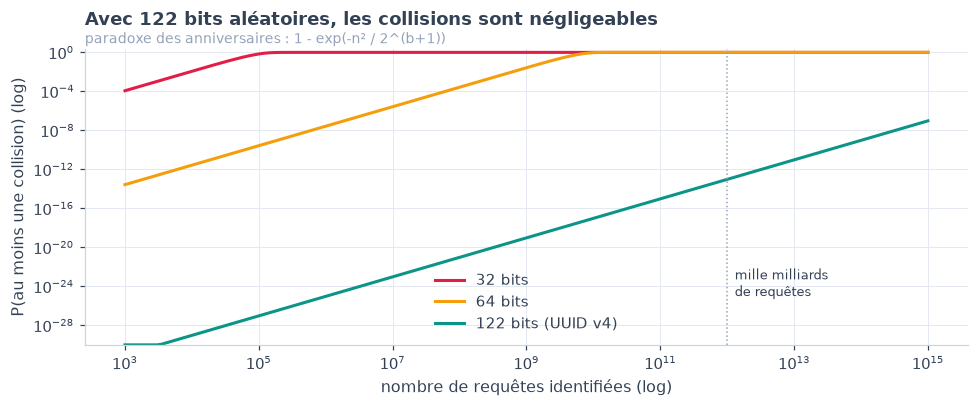

64 bits, 1e9 requêtes : 2.7% ; 122 bits, 1e12 requêtes : 9.4e-14


In [6]:
n = np.logspace(3, 15, 200)
fig, ax = plt.subplots(figsize=(9, 3.8))
for b, c, lab in [(32, ROSE, "32 bits"), (64, AMBER, "64 bits"), (122, TEAL, "122 bits (UUID v4)")]:
    pr = np.array([dfl.uuid_collision_prob(x, b) for x in n])
    ax.plot(n, np.maximum(pr, 1e-30), color=c, label=lab)
ax.axvline(1e12, color=GRAY, ls=":", lw=1); ax.text(1.3e12, 1e-25, "mille milliards\nde requêtes", fontsize=8.5, color=SLATE)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-30, 2)
ax.set_xlabel("nombre de requêtes identifiées (log)"); ax.set_ylabel("P(au moins une collision) (log)")
ax.set_title("Avec 122 bits aléatoires, les collisions sont négligeables")
subtitle(ax, "paradoxe des anniversaires : 1 - exp(-n² / 2^(b+1))")
ax.legend(); plt.tight_layout(); plt.show()
print(f"64 bits, 1e9 requêtes : {dfl.uuid_collision_prob(1e9, 64):.1%} ; 122 bits, 1e12 requêtes : {dfl.uuid_collision_prob(1e12, 122):.1e}")

Avec 32 bits, une collision devient probable dès quelques dizaines de milliers de
requêtes ; avec 64 bits, un milliard de requêtes donne déjà 2,7 % de risque ; avec les
122 bits aléatoires d'un UUID v4, même mille milliards de requêtes laissent une
probabilité de l'ordre de $10^{-13}$. L'autre option du livre, **hacher les champs du
formulaire**, a un piège différent : deux virements **légitimes** identiques (même montant,
même bénéficiaire, le même jour) auraient le même identifiant, et le second serait
ignoré. Il faut alors inclure dans le hachage un élément propre à chaque intention (un
jeton généré à l'affichage du formulaire).

> **À retenir.** Un identifiant généré **par le client** et propagé jusqu'à la base, plus
> une contrainte d'unicité, rend une requête idempotente de bout en bout ; la table des
> requêtes devient au passage un journal d'événements. 122 bits aléatoires suffisent
> largement.

## 4. L'argument de bout en bout (sections *The end-to-end argument* et *Applying end-to-end thinking in data systems*)

La suppression des doublons n'est qu'un cas d'un principe plus général, l'**argument de
bout en bout**, formulé par Saltzer, Reed et Clark en 1984. En substance : une fonction
ne peut être réalisée complètement et correctement qu'avec la connaissance et l'aide de
l'application située **aux extrémités** du système de communication ; la fournir comme
service du système de communication lui-même est donc impossible (une version partielle
fournie par les couches basses peut toutefois servir à améliorer les performances).

Ici, la fonction est la suppression des doublons : TCP la fait au niveau des paquets,
certains moteurs de flux au niveau des messages (le fameux « exactement une fois »), mais
aucun n'empêche un utilisateur de renvoyer sa requête. Il faut un identifiant transmis de
l'appareil jusqu'à la base. Le même argument vaut pour l'**intégrité** : les sommes de
contrôle d'Ethernet, de TCP et de TLS détectent la corruption **sur le réseau**, pas celle
due à un bogue logiciel aux deux bouts, ni celle du disque. Vérifions-le en faisant
voyager des enregistrements à travers une chaîne émetteur → réseau → récepteur → disque,
avec une faute injectée à un endroit, et trois mécanismes de vérification
(`dfl.e2e_pipeline`).

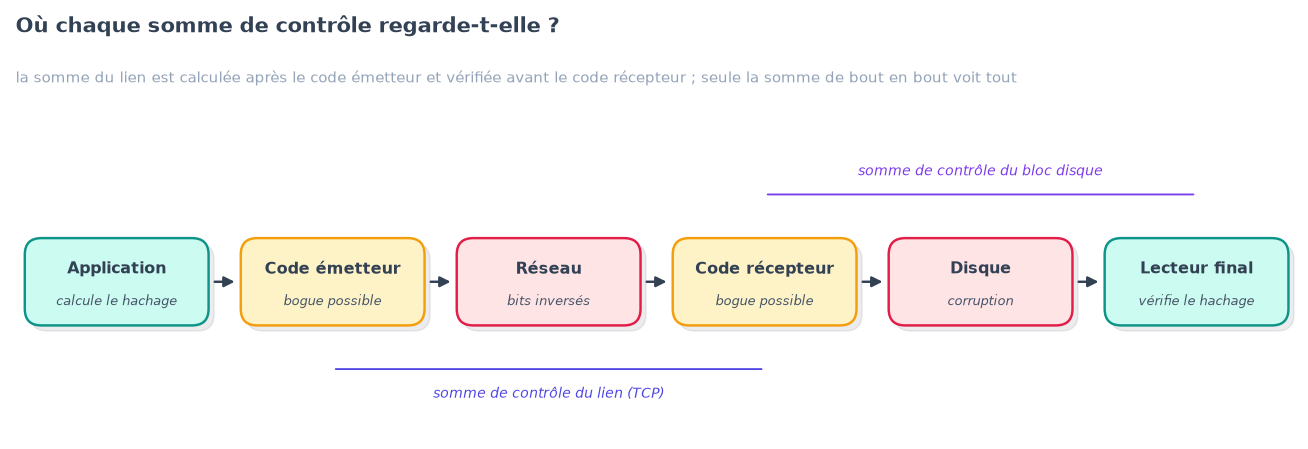

In [7]:
d = Diagram(14, 3.7, title="Où chaque somme de contrôle regarde-t-elle ?",
            subtitle="la somme du lien est calculée après le code émetteur et vérifiée avant le code récepteur ; seule la somme de bout en bout voit tout")
names = [("app", "Application", "calcule le hachage"), ("snd", "Code émetteur", "bogue possible"),
         ("net", "Réseau", "bits inversés"), ("rcv", "Code récepteur", "bogue possible"),
         ("disk", "Disque", "corruption"), ("rd", "Lecteur final", "vérifie le hachage")]
d.flow(names, y=1.7, x0=1.15, dx=2.35, w=2.0, h=0.95, colors=[TEAL, AMBER, ROSE, AMBER, ROSE, TEAL])
d.line([(3.5, 0.75), (8.2, 0.75)], color=INDIGO, style="solid", arrow=False)
d.note(5.85, 0.48, "somme de contrôle du lien (TCP)", color=INDIGO)
d.line([(8.2, 2.65), (12.9, 2.65)], color=VIOLET, style="solid", arrow=False)
d.note(10.55, 2.9, "somme de contrôle du bloc disque", color=VIOLET)
d.show()

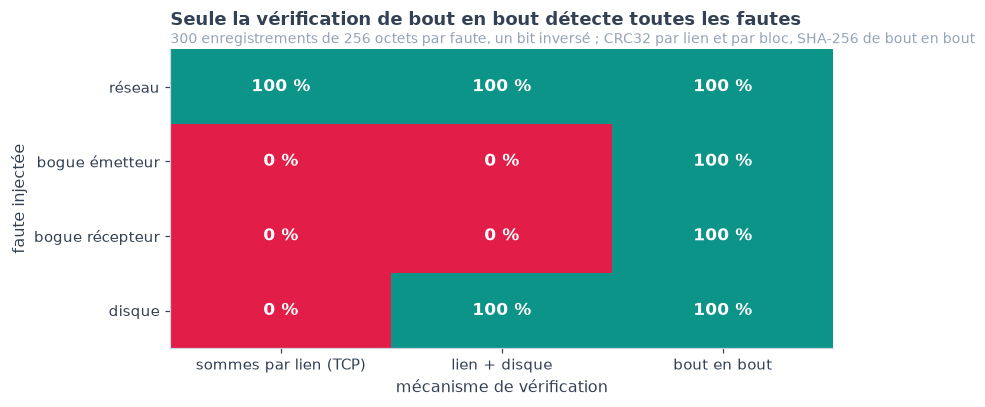

In [8]:
m = dfl.checksum_detection_matrix(n_trials=300, seed=0)
faults = list(dfl.FAULTS[1:])
schemes = list(dfl.SCHEMES)
M = np.array([[m[(f, s)] for s in schemes] for f in faults]) * 100
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(M, cmap="ddia_div", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(schemes))); ax.set_xticklabels(schemes)
ax.set_yticks(range(len(faults))); ax.set_yticklabels(faults)
for i in range(len(faults)):
    for j in range(len(schemes)):
        ax.text(j, i, f"{M[i, j]:.0f} %", ha="center", va="center", fontsize=11, fontweight="bold",
                color="white" if M[i, j] in (0, 100) else SLATE)
ax.grid(False); ax.set_xlabel("mécanisme de vérification"); ax.set_ylabel("faute injectée")
ax.set_title("Seule la vérification de bout en bout détecte toutes les fautes")
subtitle(ax, "300 enregistrements de 256 octets par faute, un bit inversé ; CRC32 par lien et par bloc, SHA-256 de bout en bout")
plt.tight_layout(); plt.show()

Chaque mécanisme de bas niveau voit **exactement** sa portion de chemin : la somme du lien
détecte 100 % des corruptions réseau et 0 % des bogues logiciels (la donnée est déjà
fausse quand la somme est calculée, ou elle le devient après la vérification) ; la somme
des blocs disque ajoute la corruption au repos. Seul le hachage calculé par l'application
d'origine et vérifié par le lecteur final attrape tout. Même raisonnement pour le
**chiffrement** :

| protection | protège contre | ne protège pas contre |
|---|---|---|
| mot de passe du WiFi | l'écoute du réseau local | les attaquants ailleurs sur Internet |
| TLS entre client et serveur | les attaquants sur le réseau | la compromission du serveur |
| chiffrement et authentification de bout en bout | tout ce qui précède | (seulement les extrémités elles-mêmes) |

Les mécanismes de bas niveau restent **utiles** : ils réduisent la probabilité des
problèmes aux niveaux supérieurs (sans TCP pour remettre les paquets dans l'ordre, les
requêtes HTTP seraient souvent mutilées). Ils ne suffisent simplement pas.

**Dans les systèmes de données.** D'où la thèse du livre : même avec des transactions
sérialisables, l'application doit prendre elle-même des mesures de bout en bout (comme la
suppression des doublons). C'est dommage, car la tolérance aux pannes est difficile à
bien faire. Les transactions sont une belle abstraction : elles réduisent une foule de
problèmes (écritures concurrentes, violations de contraintes, plantages, coupures
réseau, pannes de disque) à deux issues, valider ou annuler. Mais elles coûtent cher
entre technologies hétérogènes ; quand on y renonce, on réimplémente la tolérance aux
pannes dans le code applicatif, où elle est rarement juste, d'où des données perdues ou
corrompues. Il manque encore des abstractions qui rendent faciles les garanties de bout en
bout propres à chaque application, tout en restant performantes à grande échelle.

> **À retenir.** Une garantie (absence de doublons, intégrité, confidentialité) ne peut
> être complète que si elle est vérifiée **aux extrémités**. Les mécanismes des couches
> basses ne couvrent que leur tronçon : utiles pour la performance, insuffisants pour la
> justesse.

## 5. Faire respecter l'unicité (sections *Enforcing Constraints*, *Uniqueness constraints require consensus* et *Uniqueness in log-based messaging*)

Après les doublons, les **contraintes**. Beaucoup de fonctionnalités exigent une
**unicité** : un nom d'utilisateur ou une adresse e-mail identifie une seule personne, un
service de fichiers n'a pas deux fichiers de même nom, deux personnes ne réservent pas le
même siège. D'autres contraintes se traitent de la même façon : un solde jamais négatif,
pas plus de ventes que de stock, pas de réservations de salle qui se chevauchent.

Dans un système distribué, l'unicité exige un **consensus** (chapitre 9) :
parmi plusieurs requêtes concurrentes pour la même valeur, il faut en accepter une et
refuser les autres. La façon la plus courante : un **leader unique** qui décide de tout
(et un algorithme comme Raft pour en élire un nouveau sans cerveau partagé). On passe à
l'échelle en **partitionnant selon la valeur à rendre unique** (le hachage du nom
d'utilisateur, l'identifiant de requête). En revanche, la réplication **multi-leader
asynchrone** est exclue : deux leaders peuvent accepter en même temps deux écritures
contradictoires. Mesurons-le (`dfl.multi_leader_claims`) : 20 000 réclamations pour
5 000 noms réparties sur une journée, sur trois leaders qui ne voient les noms acceptés
par les autres qu'après un délai de réplication.

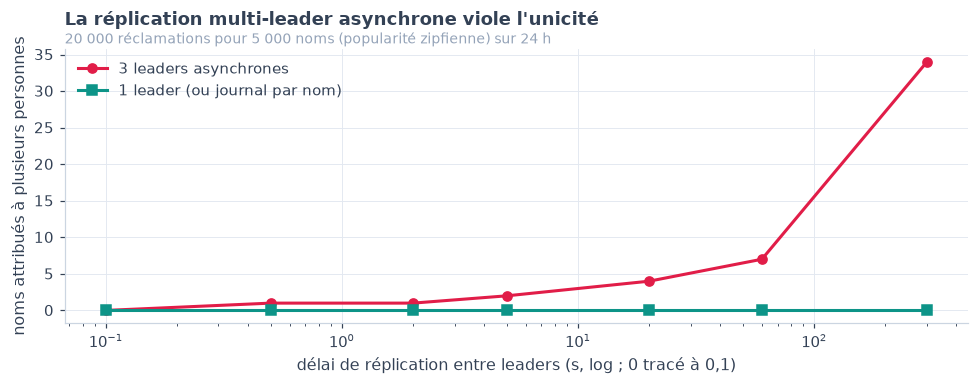

{0: 0, 0.5: 1, 2: 1, 5: 2, 20: 4, 60: 7, 300: 34}


In [9]:
rng = np.random.default_rng(1)
t_req = np.sort(rng.uniform(0, 86_400, 20_000))
names = [f"nom{x}" for x in dfl.zipf_queries(20_000, 5000, a=0.8, seed=2)]
delays = [0, 0.5, 2, 5, 20, 60, 300]
dups = {k: [dfl.multi_leader_claims(t_req, names, k, d_, seed=3) for d_ in delays] for k in (1, 3)}
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot([max(x, 0.1) for x in delays], dups[3], "o-", color=ROSE, label="3 leaders asynchrones")
ax.plot([max(x, 0.1) for x in delays], dups[1], "s-", color=TEAL, label="1 leader (ou journal par nom)")
ax.set_xscale("log"); ax.set_xlabel("délai de réplication entre leaders (s, log ; 0 tracé à 0,1)")
ax.set_ylabel("noms attribués à plusieurs personnes")
ax.set_title("La réplication multi-leader asynchrone viole l'unicité")
subtitle(ax, "20 000 réclamations pour 5 000 noms (popularité zipfienne) sur 24 h")
ax.legend(); plt.tight_layout(); plt.show()
print(dict(zip(delays, dups[3])))

Avec un délai nul, les leaders se comportent comme un seul ; dès que la réplication prend
quelques secondes, des noms populaires sont attribués deux fois, et le nombre de
doublons croît avec le délai. Pour pouvoir **refuser immédiatement** une écriture qui
viole la contrainte, une coordination **synchrone** est inévitable.

**L'unicité par un journal partitionné.** Un journal partagé garantit que tous les
consommateurs voient les messages dans le même ordre : c'est la diffusion à ordre total,
équivalente au consensus. Le dégroupage permet donc d'appliquer la même idée :

1. chaque demande de nom est un message ajouté au partition déterminé par le hachage du nom ;
2. un processeur de flux lit les demandes **séquentiellement** (un seul fil), avec une base
   locale des noms pris : il accepte le premier, refuse les suivants, et émet le verdict sur
   un flux de sortie ;
3. le client attend le verdict correspondant à sa demande sur le flux de sortie.

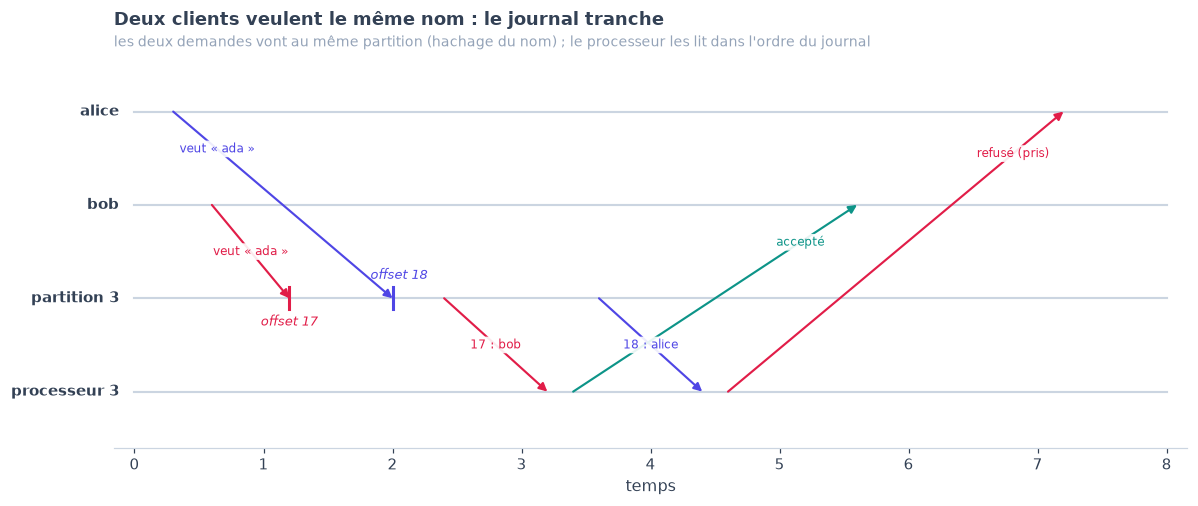

In [10]:
st = SpaceTime(["alice", "bob", SHARD + " 3", "processeur 3"], t_max=8, width=11,
               title="Deux clients veulent le même nom : le journal tranche",
               subtitle="les deux demandes vont au même " + SHARD + " (hachage du nom) ; le processeur les lit dans l'ordre du journal")
st.msg("alice", 0.3, SHARD + " 3", 2.0, "veut « ada »", color=INDIGO, label_pos=0.2)
st.msg("bob", 0.6, SHARD + " 3", 1.2, "veut « ada »", color=ROSE)
st.event(SHARD + " 3", 1.2, kind="tick", color=ROSE)
st.event(SHARD + " 3", 2.0, kind="tick", color=INDIGO)
st.note(1.2, SHARD + " 3", "offset 17", dy=-0.25, color=ROSE)
st.note(2.05, SHARD + " 3", "offset 18", dy=0.25, color=INDIGO)
st.msg(SHARD + " 3", 2.4, "processeur 3", 3.2, "17 : bob", color=ROSE)
st.msg(SHARD + " 3", 3.6, "processeur 3", 4.4, "18 : alice", color=INDIGO)
st.msg("processeur 3", 3.4, "bob", 5.6, "accepté", color=TEAL, label_pos=0.8)
st.msg("processeur 3", 4.6, "alice", 7.2, "refusé (pris)", color=ROSE, label_pos=0.85)
st.show()

C'est la construction du consensus à partir d'un journal partagé vue au chapitre
9. Elle passe à l'échelle en ajoutant des partitions, chacun étant traité
indépendamment, et elle vaut pour bien d'autres contraintes : le principe est que **toutes
les écritures susceptibles d'entrer en conflit vont au même partition** et y sont traitées
séquentiellement, avec une logique de validation arbitraire. Vérifions l'unicité et
mesurons le débit atteignable : si un processeur traite $\mu$ demandes par seconde, le
débit total est limité par le partition le plus chargé, soit $\mu / \text{part}_{\max}$.

part du nom le plus demandé : 4.3%


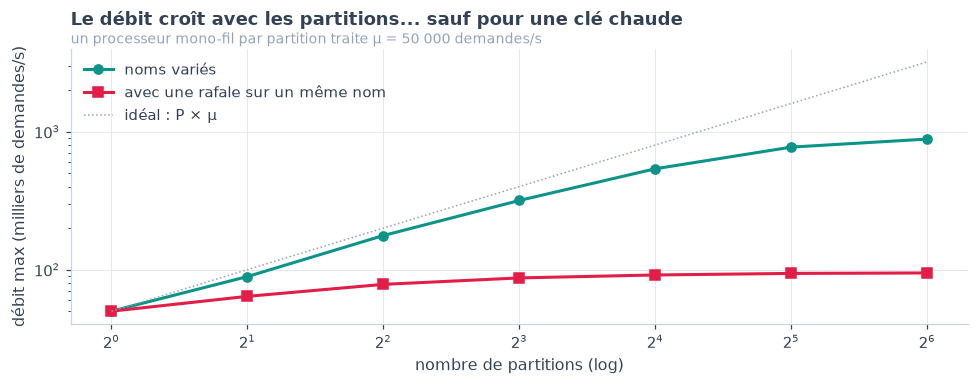

,partitions,noms en double,part du plus chargé,débit max (demandes/s)
0,1,0,1.000,50000.000
1,2,0,0.561,89094.797
2,4,0,0.283,176740.898
3,8,0,0.158,317158.262
4,16,0,0.093,538213.132
5,32,0,0.065,772200.772
6,64,0,0.057,883392.226


In [11]:
reqs = [(f"r{i}", n_) for i, n_ in enumerate(names)]
mu = 50_000
rows = []
for P in [1, 2, 4, 8, 16, 32, 64]:
    r = dfl.claim_usernames(reqs, P)
    share = max(r["per_partition"]) / len(reqs)
    rows.append({SHARDS: P, "noms en double": r["duplicates"], "part du plus chargé": share,
                 "débit max (demandes/s)": mu / share})
R = pd.DataFrame(rows)
print(f"part du nom le plus demandé : {pd.Series(names).value_counts().iloc[0] / len(names):.1%}")
hot = reqs + [(f"h{i}", "nom0") for i in range(20_000)]           # une rafale sur un seul nom très demandé
hot_rows = [mu * len(hot) / max(dfl.claim_usernames(hot, P)["per_partition"]) for P in R[SHARDS]]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(R[SHARDS], R["débit max (demandes/s)"] / 1e3, "o-", color=TEAL, label="noms variés")
ax.plot(R[SHARDS], np.array(hot_rows) / 1e3, "s-", color=ROSE, label="avec une rafale sur un même nom")
ax.plot(R[SHARDS], R[SHARDS] * mu / 1e3, color=GRAY, ls=":", lw=1, label="idéal : P × μ")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel(f"nombre de {SHARDS} (log)"); ax.set_ylabel("débit max (milliers de demandes/s)")
ax.set_title("Le débit croît avec les " + SHARDS + "... sauf pour une clé chaude")
subtitle(ax, f"un processeur mono-fil par {SHARD} traite μ = 50 000 demandes/s")
ax.legend(); plt.tight_layout(); plt.show()
R

L'unicité est garantie quel que soit le nombre de partitions (zéro doublon), et le débit croît
presque linéairement jusqu'à une quinzaine de partitions, puis s'infléchit : avec une
popularité zipfienne, le nom le plus demandé pèse à lui seul quelques pourcents des
demandes, et son partition devient le goulot. Une rafale de demandes pour **un même nom**
plafonne beaucoup plus tôt : toutes ces demandes doivent passer par le même processeur,
c'est inhérent au problème (il faut bien les ordonner). C'est la **clé chaude** du
chapitre 6.

> **À retenir.** L'unicité exige un consensus : un leader, ou, dans une architecture
> dégroupée, un journal partitionné par la valeur à rendre unique, lu séquentiellement. On
> refuse immédiatement les conflits en les faisant tous passer par le même
> partition ; le débit total croît avec le nombre de partitions, sauf pour une clé chaude.

## 6. Une requête sur plusieurs partitions, sans validation atomique (section *Multi-partition request processing*)

Plus délicat : exécuter **atomiquement** une opération qui touche plusieurs partitions tout en
respectant les contraintes. Dans le virement de la section 3, il y a potentiellement
trois partitions : celui de l'identifiant de requête, celui du payeur, celui du bénéficiaire,
sans raison d'être les mêmes. L'approche traditionnelle exige une validation atomique sur
les trois, ce qui force la transaction dans un ordre total avec toutes celles qui touchent
l'un de ces partitions : ils ne sont plus indépendants, et le débit en souffre. On peut obtenir
une justesse équivalente avec des journaux partitionnés et des processeurs de flux.

Le livre procède ainsi :

1. la requête de virement reçoit du client un identifiant unique, et est ajoutée à une
   partition du journal choisie selon cet identifiant ;
2. un processeur de flux lit le journal des requêtes et émet, pour chacune, deux
   messages : une instruction de **débit** vers la partition du payeur, une instruction de
   **crédit** vers celle du bénéficiaire, toutes deux portant l'identifiant d'origine ;
3. d'autres processeurs consomment les instructions de débit et de crédit, les
   dédupliquent par identifiant, et appliquent les changements aux soldes.

Pour empêcher un découvert, le livre suggère d'ajouter un processeur **partitionné par
compte payeur**, qui tient les soldes et valide les requêtes avant qu'elles ne soient
placées dans le journal des requêtes. Notre implémentation fusionne ces deux idées :
la requête est ajoutée directement à la partition du payeur, dont le processeur vérifie
le solde puis émet débit et crédit (et des frais, pour avoir trois destinataires).

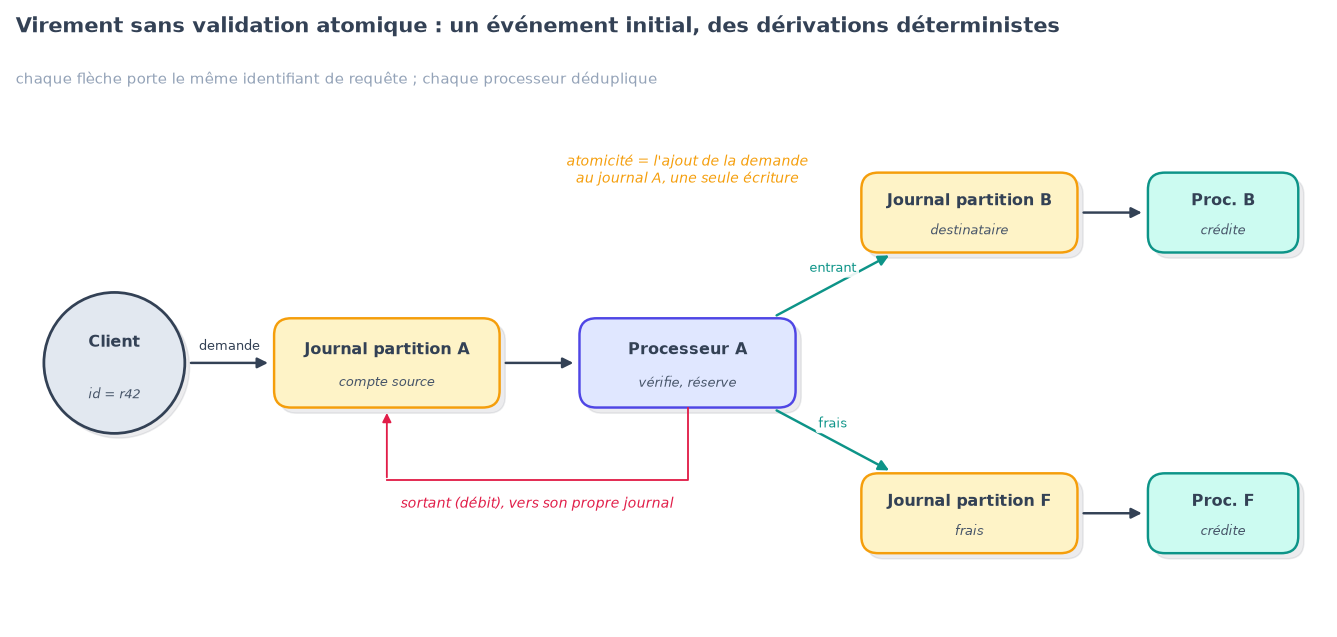

In [12]:
d = Diagram(14, 5.6, title="Virement sans validation atomique : un événement initial, des dérivations déterministes",
            subtitle="chaque flèche porte le même identifiant de requête ; chaque processeur déduplique")
d.box("cli", 1.1, 2.8, "Client", sub="id = r42", kind="user", color=SLATE, w=1.5)
d.box("ls", 4.0, 2.8, f"Journal {SHARD} A", sub="compte source", color=AMBER, w=2.4, h=0.95)
d.box("ps", 7.2, 2.8, "Processeur A", sub="vérifie, réserve", color=INDIGO, w=2.3, h=0.95)
d.box("lb", 10.2, 4.4, f"Journal {SHARD} B", sub="destinataire", color=AMBER, w=2.3, h=0.85)
d.box("lf", 10.2, 1.2, f"Journal {SHARD} F", sub="frais", color=AMBER, w=2.3, h=0.85)
d.box("pb", 12.9, 4.4, "Proc. B", sub="crédite", color=TEAL, w=1.6, h=0.85)
d.box("pf", 12.9, 1.2, "Proc. F", sub="crédite", color=TEAL, w=1.6, h=0.85)
d.arrow("cli", "ls", "demande")
d.arrow("ls", "ps")
d.arrow("ps", "lb", "entrant", color=TEAL)
d.arrow("ps", "lf", "frais", color=TEAL)
d.line([(7.2, 2.32), (7.2, 1.55), (4.0, 1.55), (4.0, 2.3)], color=ROSE, style="solid")
d.note(5.6, 1.3, "sortant (débit), vers son propre journal", color=ROSE)
d.arrow("lb", "pb"); d.arrow("lf", "pf")
d.note(7.2, 4.85, "atomicité = l'ajout de la demande\nau journal A, une seule écriture", color=AMBER)
d.show()

Exigences : les événements d'un compte sont traités strictement dans l'ordre du journal,
avec une livraison **au moins une fois**, par des processeurs **déterministes**. Si le
processeur A plante en plein traitement, ses messages de sortie ont pu partir ou non ;
après reprise, il retraite la même demande (au moins une fois), prend la même décision
(déterministe) et réémet les mêmes messages avec le même identifiant ; les consommateurs
en aval ignorent les doublons.

Mettons-le à l'épreuve (`dfl.PaymentSystem`) : 40 comptes de 100 EUR répartis sur 4
partitions, 3 000 virements aléatoires de 1 à 60 EUR avec 1 EUR de frais, et des
processeurs qui plantent avec une probabilité $p$ à chaque événement, **après avoir émis
une partie aléatoire de leurs sorties** (l'état et l'offset ne sont validés qu'ensemble,
à la fin du traitement : un point de reprise).

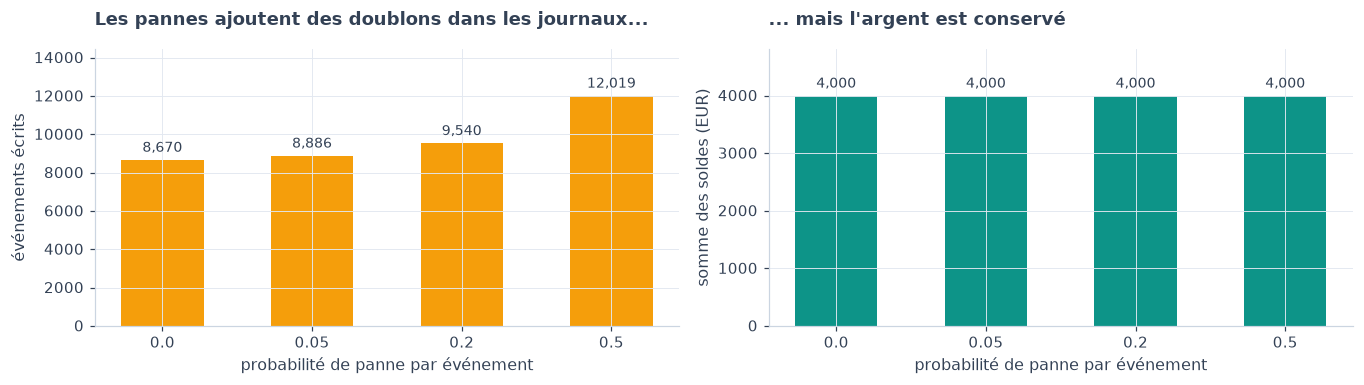

,p (panne par événement),pannes,virements acceptés,refusés (solde insuffisant),somme des soldes,solde minimal,événements dans les journaux,statuts en double
0,0.00,0,1890,1110,4000.0,0.0,8670,0
1,0.05,476,1890,1110,4000.0,0.0,8886,58
2,0.20,2392,1890,1110,4000.0,0.0,9540,233
3,0.50,12255,1890,1110,4000.0,0.0,12019,904


In [13]:
def run_payments(p_crash, seed=0, n=3000):
    rng = random.Random(seed)
    accts = {f"c{i:02d}": 100.0 for i in range(40)}
    ps_ = dfl.PaymentSystem(dict(accts), n_shards=4, fee=1.0)
    for i in range(n):
        a, b = rng.sample(sorted(accts), 2)
        ps_.submit(f"r{i}", a, b, float(rng.randint(1, 60)))
        if i % 50 == 49:                              # les demandes arrivent par vagues de 50
            ps_.run(seed=seed + i, p_crash=p_crash)
    ps_.run(seed=seed + n, p_crash=p_crash)
    return ps_

rows = []
for p in [0.0, 0.05, 0.2, 0.5]:
    ps_ = run_payments(p)
    chk = ps_.check()
    rows.append({"p (panne par événement)": p, "pannes": ps_.crashes, "virements acceptés": chk["accepted"],
                 "refusés (solde insuffisant)": chk["refused"], "somme des soldes": chk["total"],
                 "solde minimal": chk["min_balance"], "événements dans les journaux": chk["log_events"],
                 "statuts en double": chk["status_dups"]})
R = pd.DataFrame(rows)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6))
ax1.bar(R.iloc[:, 0].astype(str), R["événements dans les journaux"], color=AMBER, width=0.55)
annotate_bars(ax1, "{:,.0f}")
ax1.set_ylim(0, R["événements dans les journaux"].max() * 1.2)
ax1.set_xlabel("probabilité de panne par événement"); ax1.set_ylabel("événements écrits")
ax1.set_title("Les pannes ajoutent des doublons dans les journaux...")
ax2.bar(R.iloc[:, 0].astype(str), R["somme des soldes"], color=TEAL, width=0.55)
annotate_bars(ax2, "{:,.0f}")
ax2.set_ylim(0, 4800)
ax2.set_xlabel("probabilité de panne par événement"); ax2.set_ylabel("somme des soldes (EUR)")
ax2.set_title("... mais l'argent est conservé")
plt.tight_layout(); plt.show()
R

Même quand un processeur plante un événement sur deux, la somme des soldes (frais
compris) reste **exactement** 4 000 EUR, aucun solde ne devient négatif, et chaque
virement reçoit un verdict. Les pannes se voient seulement dans les journaux, qui
contiennent des événements réémis (et le client reçoit parfois son statut en double,
qu'il déduplique lui aussi par identifiant). Le nombre de virements acceptés est
identique dans les quatre cas : chaque processeur est déterministe et, ici, chaque vague
est entièrement traitée avant l'arrivée de la suivante, si bien que la position des
crédits dans chaque journal ne dépend pas des pannes. Dans un système qui tourne en
continu, les pannes pourraient changer le moment où un crédit arrive sur un compte, et
un virement refusé dans un scénario serait peut-être accepté dans un autre ; chaque
décision resterait valide au regard du solde vu par le processeur, ce qui est la
garantie demandée.

L'**atomicité** ne vient pas d'une transaction, mais du fait que l'**ajout de la demande**
au journal du compte source est une action atomique : une fois cet événement dans le
journal, tous les événements en aval finiront par être écrits (après des reprises,
peut-être en double, mais ils apparaîtront). Avec une sémantique exactement une fois du
moteur de flux, c'est encore plus simple : l'état local du processeur reste cohérent avec
les messages traités. Le client qui veut connaître l'issue s'abonne au flux des statuts.

En découpant la transaction multi-partition en étapes partitionnées différemment, reliées par
un identifiant de bout en bout, on obtient la même propriété de justesse (chaque requête
appliquée exactement une fois au payeur et au bénéficiaire) **sans protocole de
validation atomique**.

> **À retenir.** Un événement initial écrit atomiquement, des dérivations déterministes,
> un identifiant propagé partout et des consommateurs qui dédupliquent : on obtient
> l'effet d'une transaction multi-partition sans coordination entre partitions, et les pannes ne
> laissent que des doublons inoffensifs.

## Synthèse

- Les garanties d'une base ne protègent pas des bogues applicatifs ; l'**immuabilité**
  rend la réparation possible.
- Une relance de l'utilisateur traverse TCP, la base et le 2PC : chaque réponse perdue
  devient une exécution en double, sauf avec un **identifiant de requête de bout en bout**
  et une contrainte d'unicité (chapitre 7).
- L'**argument de bout en bout** : une garantie n'est complète que vérifiée aux extrémités ;
  les couches basses (sommes de contrôle, TLS) ne couvrent que leur tronçon.
- L'**unicité** exige un consensus (chapitre 9) ; un journal
  partitionné par la valeur à rendre unique le fournit et passe à l'échelle.
- Une transaction multi-partition peut être remplacée par un événement initial atomique et des
  étapes déterministes qui dédupliquent.

Le cours 5 distingue deux sens du mot « cohérence » (ponctualité et intégrité), montre
que beaucoup de contraintes peuvent être vérifiées **après coup**, et propose de **vérifier**
l'intégrité plutôt que de la supposer.